In [36]:
pip install MetaTrader5

Note: you may need to restart the kernel to use updated packages.


In [37]:
%pip install -q arch statsmodels seaborn scipy

Note: you may need to restart the kernel to use updated packages.


In [38]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, probplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss
from arch import arch_model

try:
    from IPython.display import display
except ImportError:          # running as a plain .py file
    display = print

# =====================================================================
#  CONFIG  - the ONLY cell you need to edit
# =====================================================================
DATA_SOURCE = "csv"                   # "yfinance"  or  "csv"

# ---- if DATA_SOURCE == "yfinance" ----
TICKER     = "XAUUSDm"
START_DATE = "2020-01-01"
END_DATE   = "2026-09-15"             # None = up to today

# ---- if DATA_SOURCE == "csv" ----
CSV_PATH     = "mt5_XAUUSDm_M1.csv"   # price CSV, differenced CSV or returns CSV
CSV_KIND     = "auto"                 # "auto" | "price" | "diff" | "returns"
DATE_COLUMN  = None                   # None = auto-detect
VALUE_COLUMN = None                   # None = auto-detect
ANCHOR_PRICE = None                   # LAST real price. Only for diff/returns CSV, to get price forecasts
RETURNS_IN_PERCENT = False            # only used when the CSV holds returns (1.2 means 1.2 %)

# ---- common ----
FORECAST_HORIZON       = 15           # bars ahead
DROP_SESSION_OPEN_BARS = True         # intraday data only: drop the first bar after every time gap (overnight/weekend/break)

In [39]:
import time
import MetaTrader5 as mt5
from IPython.display import clear_output

MT5_SYMBOL       = "XAUUSDm"
MT5_TIMEFRAME    = mt5.TIMEFRAME_H1     # use mt5.TIMEFRAME_M1 for 1-minute bars
MT5_HISTORY_BARS = 10000
MT5_LOGIN, MT5_PASSWORD, MT5_SERVER = None, None, None


def mt5_connect():
    if MT5_LOGIN is None:
        ok = mt5.initialize()
    else:
        ok = mt5.initialize(login=MT5_LOGIN, password=MT5_PASSWORD, server=MT5_SERVER)
    if not ok:
        raise RuntimeError(f"MT5 initialize failed: {mt5.last_error()}  "
                           "-> is the MT5 terminal installed, open, and logged in to your demo account?")
    if not mt5.symbol_select(MT5_SYMBOL, True):
        raise RuntimeError(f"Symbol '{MT5_SYMBOL}' not found: {mt5.last_error()}  -> copy the exact name from Market Watch")
    acc = mt5.account_info()
    print("Connected to MT5:", getattr(acc, "server", "?"), "| symbol:", MT5_SYMBOL)


def mt5_bars(n):
    """Last n CLOSED bars as a DataFrame indexed by time (position 1 skips the still-forming bar)."""
    rates = mt5.copy_rates_from_pos(MT5_SYMBOL, MT5_TIMEFRAME, 1, n)
    if rates is None or len(rates) == 0:
        raise RuntimeError(f"No bars returned: {mt5.last_error()}")
    d = pd.DataFrame(rates)
    d["time"] = pd.to_datetime(d["time"], unit="s")      # broker SERVER time (not UTC / not IST)
    return d.set_index("time")

In [40]:
mt5_connect()
hist = mt5_bars(MT5_HISTORY_BARS)
MT5_CSV = f"mt5_{MT5_SYMBOL}_M1.csv"      # the name says M1 but holds whatever timeframe you chose; Cell 2 expects this name
hist[["open", "high", "low", "close", "tick_volume"]].to_csv(MT5_CSV)
print(f"{len(hist)} bars  |  {hist.index[0]}  ->  {hist.index[-1]}")
print(f"Saved: {MT5_CSV}")
display(hist.tail())
mt5.shutdown()

Connected to MT5: Exness-MT5Trial6 | symbol: XAUUSDm
10000 bars  |  2025-02-07 09:00:00  ->  2026-10-16 15:00:00
Saved: mt5_XAUUSDm_M1.csv


,open,high,low,close,tick_volume,spread,real_volume
time,,,,,,,
2026-10-16 11:00:00,4174.208,4182.139,4171.066,4171.952,7549,240,0
2026-10-16 12:00:00,4171.841,4181.492,4162.894,4166.812,11139,240,0
2026-10-16 13:00:00,4166.758,4189.995,4154.592,4185.117,20140,240,0
2026-10-16 14:00:00,4185.242,4198.958,4181.180,4185.353,21576,240,0
2026-10-16 15:00:00,4185.390,4187.540,4167.535,4167.917,15954,240,0


True

In [41]:
# ---------------------------------------------------------------------
#  Helper functions (run once, nothing to edit)
# ---------------------------------------------------------------------
PRICE_HINTS = ["adj close", "adj_close", "adjclose", "close", "closing", "price", "ltp", "last"]
DIFF_HINTS  = ["diff", "change", "delta", "chg"]
RET_HINTS   = ["return", "ret", "pct"]
DATE_HINTS  = ["date", "time", "timestamp", "datetime", "day", "unnamed: 0"]
SKIP_HINTS  = ["volume", "turnover", "qty", "unnamed", "open int"]
SKIP_EXACT  = {"vol", "oi", "index", "idx", "sno", "s.no", "#"}
_TZ_TAIL    = re.compile(r"(\d{2}:\d{2}(?::\d{2}(?:\.\d+)?)?)\s*(?:Z|[+-]\d{2}:?\d{2})$")


def _num(col):
    """Text -> float. Understands '1,234.50', rupee/dollar signs, blanks, junk rows."""
    if pd.api.types.is_numeric_dtype(col):
        return pd.to_numeric(col, errors="coerce")
    txt = col.astype(str).str.replace(r"[,\s₹$€£]", "", regex=True)
    return pd.to_numeric(txt, errors="coerce")


def _to_dt(txt, **kw):
    try:
        return pd.to_datetime(txt, errors="coerce", format="mixed", **kw)
    except (TypeError, ValueError):
        return pd.to_datetime(txt, errors="coerce", **kw)


def _parse_dates(col):
    """Parses dates. Drops time-zone offsets (keeps local wall-clock time).
    For dd-mm-yyyy vs mm-dd-yyyy it tries both and keeps the reading with fewer failures / most ordered dates."""
    txt = col.astype(str).str.strip().str.replace(_TZ_TAIL, r"\1", regex=True)
    if txt.str.match(r"^\d{4}-\d{1,2}-\d{1,2}").mean() > 0.9:         # ISO: 2026-10-15 [09:15:00]
        return pd.to_datetime(txt, errors="coerce", format="ISO8601")

    def quality(d):
        ok = d.notna()
        up = (d[ok].diff().dropna() > pd.Timedelta(0)).mean() if ok.sum() > 2 else 1.0
        return (round(1 - ok.mean(), 3), -max(up, 1 - up))          # fewest NaT, then most ordered

    return min([_to_dt(txt), _to_dt(txt, dayfirst=True)], key=quality)


def _read_table(path):
    last_err = None
    for enc in ("utf-8-sig", "latin-1"):
        try:
            with open(path, encoding=enc) as fh:
                head = fh.readline()
            sep = next((d for d in (";", "\t", "|") if head.count(d) > head.count(",")), ",")
            return pd.read_csv(path, sep=sep, encoding=enc, skip_blank_lines=True)
        except UnicodeDecodeError as err:
            last_err = err
    raise last_err


def _match_col(raw, name):
    for c in raw.columns:
        if c.strip().lower() == str(name).strip().lower():
            return c
    raise KeyError(f"Column '{name}' not found. Available columns: {list(raw.columns)}")


def _pick_date_column(raw, wanted):
    if wanted is not None:
        return _match_col(raw, wanted)
    hinted = [c for c in raw.columns if any(h in c.lower() for h in DATE_HINTS)]
    others = [c for c in raw.columns if c not in hinted]
    for c in hinted + others:
        if _num(raw[c]).notna().mean() > 0.9:          # numeric column = values, not dates
            continue
        if _parse_dates(raw[c]).notna().mean() > 0.8:
            return c
    return None                                         # no date column -> plain 0,1,2,... index


def _pick_value_column(raw, date_col, wanted, kind):
    if wanted is not None:
        return _match_col(raw, wanted)
    cands = [c for c in raw.columns if c != date_col and _num(raw[c]).notna().mean() >= 0.8]
    if not cands:
        raise ValueError(f"No numeric column found. Columns are: {list(raw.columns)}")
    junk = lambda c: c.lower() in SKIP_EXACT or any(h in c.lower() for h in SKIP_HINTS)
    cands = [c for c in cands if not junk(c)] or cands
    if kind in ("price", "auto"):                       # prefer 'Close' over 'Close_diff'
        plain = [c for c in cands if not any(h in c.lower() for h in DIFF_HINTS + RET_HINTS)]
        cands = plain or cands
    order = {"price": PRICE_HINTS,
             "diff": DIFF_HINTS + PRICE_HINTS,
             "returns": RET_HINTS + PRICE_HINTS}.get(kind, PRICE_HINTS + DIFF_HINTS + RET_HINTS)
    for h in order:
        for c in cands:
            if h in c.lower():
                return c
    return cands[0]


def read_csv_series(path, date_col=None, value_col=None, kind="auto"):
    """Any reasonable CSV -> clean, sorted float Series (+ the date/value column names used)."""
    raw = _read_table(path)
    raw.columns = [str(c).strip() for c in raw.columns]
    dcol = _pick_date_column(raw, date_col)
    vcol = _pick_value_column(raw, dcol, value_col, kind)
    values = _num(raw[vcol]).to_numpy(dtype=float)
    if dcol is not None:
        idx = pd.DatetimeIndex(_parse_dates(raw[dcol]))
        s = pd.Series(values, index=idx, name=vcol)
        s = s[idx.notna()]                              # drops header-junk rows such as 'Ticker', 'Date'
        s = s.replace([np.inf, -np.inf], np.nan).dropna()
        s = s[~s.index.duplicated(keep="last")].sort_index()
    else:
        s = pd.Series(values, name=vcol).replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    return s, dcol, vcol


def detect_kind(s, path, vcol):
    """Decide: price level, price differences, or returns."""
    names = f"{Path(path).stem} {vcol}".lower()
    says_diff = any(h in names for h in DIFF_HINTS)
    says_ret = any(h in names for h in RET_HINTS)
    if s.min() > 0:
        why = "all values are positive -> price level"
        if says_diff or says_ret:
            why += " (the name says diff/returns, but a differenced series cannot be all positive)"
        return "price", why
    if says_diff:
        return "diff", "file/column name says difference"
    if says_ret:
        return "returns", "file/column name says returns"
    if s.abs().quantile(0.99) <= 0.5:
        return "returns", "values have both signs and are tiny (|x| <= 0.5) -> decimal returns"
    return "diff", "values have both signs -> price differences"


def load_yfinance(ticker, start, end):
    import yfinance as yf
    raw = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
    if raw is None or len(raw) == 0:
        raise ValueError(f"yfinance returned no data for '{ticker}'. Check the ticker, dates and internet.")
    if isinstance(raw.columns, pd.MultiIndex):          # ('Close', 'MSFT') -> 'Close'
        raw.columns = raw.columns.get_level_values(0)
    col = "Adj Close" if "Adj Close" in raw.columns else "Close"
    s = raw[col]
    if isinstance(s, pd.DataFrame):
        s = s.iloc[:, 0]
    s = s.astype(float).dropna()
    s.index = pd.DatetimeIndex(s.index)
    if s.index.tz is not None:
        s.index = s.index.tz_localize(None)
    return s


def get_bar_kind(index):
    if not isinstance(index, pd.DatetimeIndex) or len(index) < 3:
        return "none"
    step = pd.Series(index).diff().median()
    if step < pd.Timedelta(hours=20):
        return "intraday"
    if step <= pd.Timedelta(days=4):
        return "daily"
    return "periodic"                                   # weekly / monthly


def prepare(s, kind, anchor=None, returns_in_percent=False, drop_open=False):
    """Builds df['Close'] (price level) and df['Series'] (the stationary series GARCH will model)."""
    s = s.astype(float)
    if kind == "price":
        bad = int((s <= 0).sum())
        if bad:
            print(f"WARNING: removed {bad} non-positive price(s)")
            s = s[s > 0]
        price, y, mode = s, s.pct_change(), "pct"
    elif kind == "returns":
        if not returns_in_percent and s.abs().quantile(0.99) > 0.5:
            print("WARNING: these 'returns' look like percentages (large values). "
                  "If so, set RETURNS_IN_PERCENT = True.")
        y = s / 100.0 if returns_in_percent else s
        if (y <= -1).any():
            raise ValueError("Some returns are <= -100%. If the file is in percent, set RETURNS_IN_PERCENT = True.")
        growth = (1 + y).cumprod()
        price = (1.0 if anchor is None else float(anchor)) * growth / growth.iloc[-1]
        mode = "pct"
    elif kind == "diff":
        y, mode = s, "abs"
        price = (0.0 if anchor is None else float(anchor)) - (s.sum() - s.cumsum())
    else:
        raise ValueError("kind must be 'price', 'diff' or 'returns'")

    df = pd.DataFrame({"Close": price, "Series": y}).replace([np.inf, -np.inf], np.nan).dropna()
    bar = get_bar_kind(df.index)
    if drop_open and bar == "intraday":
        # the first bar after any time gap (overnight, weekend, daily break) holds the GAP move, not a normal bar move
        step = pd.Series(df.index, index=df.index).diff()
        after_gap = (step > 5 * step.median()).to_numpy()
        print(f"Dropped {int(after_gap.sum())} bars that follow a time gap (overnight / weekend / break)")
        df = df[~after_gap]
    if len(df) < 50:
        raise ValueError(f"Only {len(df)} usable rows - GARCH needs at least ~250.")
    if len(df) < 250:
        print(f"WARNING: only {len(df)} rows. GARCH estimates will be unstable below ~250.")
    return df, mode, bar


def choose_scale(y, mode):
    """Multiplier that puts the series on a nice scale for the optimiser.
    Returns -> percent (x100). Anything else -> power of 10 that brings the std into [1, 10)."""
    sd = float(y.std())
    if not np.isfinite(sd) or sd <= 0:
        raise ValueError("The series is empty or constant - check the CSV and the column choice.")
    if mode == "pct" and 0.002 <= sd <= 0.3:
        return 100.0
    return float(10.0 ** np.ceil(-np.log10(sd)))


def make_forecast_index(index, horizon, bar_kind):
    if bar_kind == "daily":
        return pd.bdate_range(index[-1] + pd.Timedelta(days=1), periods=horizon)
    if bar_kind == "periodic":
        step = pd.Series(index).diff().median()
        return pd.DatetimeIndex([index[-1] + step * (i + 1) for i in range(horizon)])
    return pd.RangeIndex(1, horizon + 1, name="bars ahead")   # intraday / no dates: count bars


def xs(index):
    """x-values for plots. Intraday: bar number, so overnight/weekend gaps do not stretch the axis."""
    return np.arange(len(index)) if BAR_KIND == "intraday" else index


def fit_garch(y, dist):
    am = arch_model(y, mean="Constant", vol="GARCH", p=1, q=1, dist=dist, rescale=False)
    res = am.fit(disp="off")
    if res.convergence_flag != 0:
        print(f"WARNING ({dist}): optimiser did not converge cleanly (flag {res.convergence_flag}).")
    return res


def residual_diagnostics(fit, label, dist):
    """Same plots as the original notebook + Ljung-Box numbers."""
    z = (fit.resid / fit.conditional_volatility).dropna()
    lags = max(5, min(50, len(z) // 2 - 1))
    nu = float(fit.params["nu"]) if dist == "t" else None

    plt.figure(figsize=(14, 6))
    plt.plot(xs(z.index), z.values)
    plt.title(f"{ticker} {label} Standardized Residuals")
    plt.xlabel(XLABEL); plt.ylabel("Standardized Residuals"); plt.grid(True); plt.show()

    plt.figure(figsize=(10, 6))
    sns.histplot(z, bins=50, kde=True, color="purple")
    plt.title(f"Histogram of {ticker} {label} Standardized Residuals")
    plt.xlabel("Standardized Residuals"); plt.ylabel("Frequency"); plt.grid(True); plt.show()

    plt.figure(figsize=(8, 8))
    if dist == "t":      # arch's t has unit variance; rescale to a standard Student-t so points sit on the line
        probplot(z * np.sqrt(nu / (nu - 2)), dist="t", sparams=(nu,), plot=plt)
        plt.title(f"Student's t QQ Plot of {ticker} {label} Standardized Residuals (nu={nu:.1f})")
    else:
        probplot(z, dist="norm", plot=plt)
        plt.title(f"Normal QQ Plot of {ticker} {label} Standardized Residuals")
    plt.grid(True); plt.show()

    for data, nm in ((z, "Standardized Residuals"), (z ** 2, "Squared Standardized Residuals")):
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        plot_acf(data, lags=lags, ax=axes[0], title=f"ACF of {ticker} {label} {nm}")
        plot_pacf(data, lags=lags, ax=axes[1], method="ywm", title=f"PACF of {ticker} {label} {nm}")
        plt.tight_layout(); plt.show()

    k = max(1, min(10, len(z) // 5))
    p1 = float(acorr_ljungbox(z, lags=[k])["lb_pvalue"].iloc[0])
    p2 = float(acorr_ljungbox(z ** 2, lags=[k])["lb_pvalue"].iloc[0])
    print(f"Ljung-Box on residuals          (lag {k}): p = {p1:.4f}  ->",
          "OK, no autocorrelation left" if p1 > 0.05 else "autocorrelation left in the mean")
    print(f"Ljung-Box on squared residuals  (lag {k}): p = {p2:.4f}  ->",
          "OK, volatility clustering captured" if p2 > 0.05 else "ARCH effects left, try GARCH(1,2) / EGARCH")

In [42]:
# ---------------------------------------------------------------------
#  Load data -> df['Close'] (price level) and df['Series'] (stationary series for GARCH)
# ---------------------------------------------------------------------
if DATA_SOURCE == "yfinance":
    raw_series = load_yfinance(TICKER, START_DATE, END_DATE)
    ticker = TICKER
    KIND, why = "price", "downloaded from yfinance"
    src_note = f"yfinance {TICKER}"
elif DATA_SOURCE == "csv":
    raw_series, date_col_used, value_col_used = read_csv_series(CSV_PATH, DATE_COLUMN, VALUE_COLUMN, CSV_KIND)
    ticker = Path(CSV_PATH).stem
    if CSV_KIND == "auto":
        KIND, why = detect_kind(raw_series, CSV_PATH, value_col_used)
    else:
        KIND, why = CSV_KIND, "set by CSV_KIND"
    src_note = f"{CSV_PATH}  (date column: {date_col_used}, value column: {value_col_used})"
else:
    raise ValueError("DATA_SOURCE must be 'yfinance' or 'csv'")

df, MODE, BAR_KIND = prepare(raw_series, KIND, ANCHOR_PRICE, RETURNS_IN_PERCENT, DROP_SESSION_OPEN_BARS)
SCALE = choose_scale(df["Series"], MODE)
df["Series"] = df["Series"] * SCALE            # model units (e.g. % for stock returns)
df["Squared"] = df["Series"] ** 2

# labels used by the plots
if MODE == "pct":
    SERIES_LABEL = {100.0: "Returns (%)", 10000.0: "Returns (bps)"}.get(SCALE, f"Returns (x{SCALE:g})")
else:
    SERIES_LABEL = "Price change" + ("" if SCALE == 1 else f" (x{SCALE:g})")
if KIND == "price":
    PRICE_LABEL = "Adjusted Close Price"
elif ANCHOR_PRICE is not None:
    PRICE_LABEL = "Price (rebuilt from ANCHOR_PRICE)"
else:
    PRICE_LABEL = "Cumulative change vs last point (0 = last)" if MODE == "abs" else "Index level (last = 1)"
XLABEL = "Bar number (gaps removed)" if BAR_KIND == "intraday" else "Date"

print(f"Source      : {src_note}")
print(f"Input kind  : {KIND}   <- {why}")
print(f"Model series: {SERIES_LABEL}   |   scale x{SCALE:g}   |   mode: {MODE}   |   bars: {BAR_KIND}")
print(f"Rows        : {len(df)}   from {df.index[0]}  to  {df.index[-1]}")
if KIND != "price" and ANCHOR_PRICE is None:
    print("Note        : no ANCHOR_PRICE given, so price forecasts are relative to the last point.")
print()
display(df.head())

Dropped 90 bars that follow a time gap (overnight / weekend / break)
Source      : mt5_XAUUSDm_M1.csv  (date column: time, value column: close)
Input kind  : price   <- all values are positive -> price level
Model series: Returns (%)   |   scale x100   |   mode: pct   |   bars: intraday
Rows        : 9909   from 2025-02-07 10:00:00  to  2026-10-16 15:00:00



,Close,Series,Squared
time,,,
2025-02-07 10:00:00,2867.514,-0.050924,0.002593
2025-02-07 11:00:00,2867.628,0.003976,0.000016
2025-02-07 12:00:00,2863.611,-0.140081,0.019623
2025-02-07 13:00:00,2862.492,-0.039077,0.001527
2025-02-07 14:00:00,2876.673,0.495407,0.245429


In [43]:
# ---------------------------------------------------------------------
#  Stationarity check on the series GARCH will model (ADF + KPSS)
# ---------------------------------------------------------------------
y = df["Series"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    max_lag = min(20, int(np.ceil(12 * (len(y) / 100) ** 0.25)))   # cap: huge files (350k+ bars) otherwise run out of memory
    adf_stat, adf_p = adfuller(y, maxlag=max_lag, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(y, regression="c", nlags="auto")[:2]

print(f"ADF  : statistic = {adf_stat:.3f}, p = {adf_p:.4f}   (p < 0.05  -> stationary)")
print(f"KPSS : statistic = {kpss_stat:.3f}, p = {kpss_p:.4f}   (p > 0.05  -> stationary)")
if adf_p < 0.05 and kpss_p > 0.05:
    print("VERDICT: STATIONARY - ready for GARCH.")
elif adf_p < 0.05:
    print("VERDICT: mostly stationary (ADF passes, KPSS flags mild instability) - usual for financial data, OK to continue.")
else:
    print("VERDICT: NOT STATIONARY.")
    if KIND != "price":
        print("  -> The file looks like a price LEVEL, not differences. Set CSV_KIND = 'price' and re-run from the config cell.")
    else:
        print("  -> Check for bad ticks or a structural break in the data.")

ADF  : statistic = -30.183, p = 0.0000   (p < 0.05  -> stationary)
KPSS : statistic = 0.252, p = 0.1000   (p > 0.05  -> stationary)
VERDICT: STATIONARY - ready for GARCH.


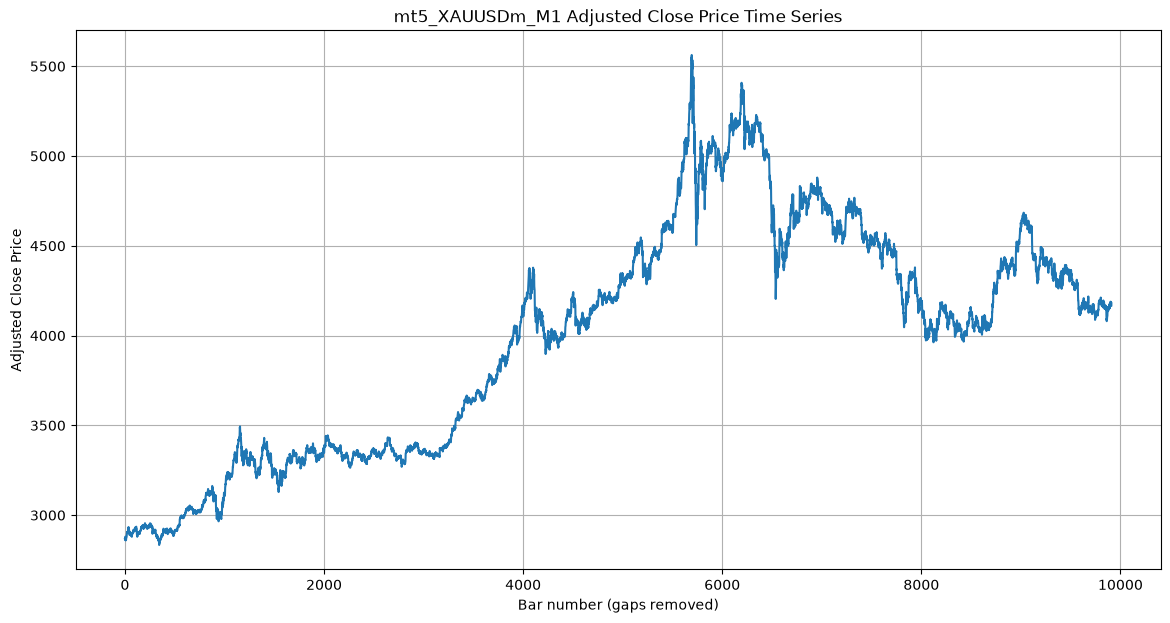

In [44]:
plt.figure(figsize=(14, 7))
plt.plot(xs(df.index), df["Close"].values)
plt.title(f"{ticker} {PRICE_LABEL} Time Series")
plt.xlabel(XLABEL)
plt.ylabel(PRICE_LABEL)
plt.grid(True)
plt.show()

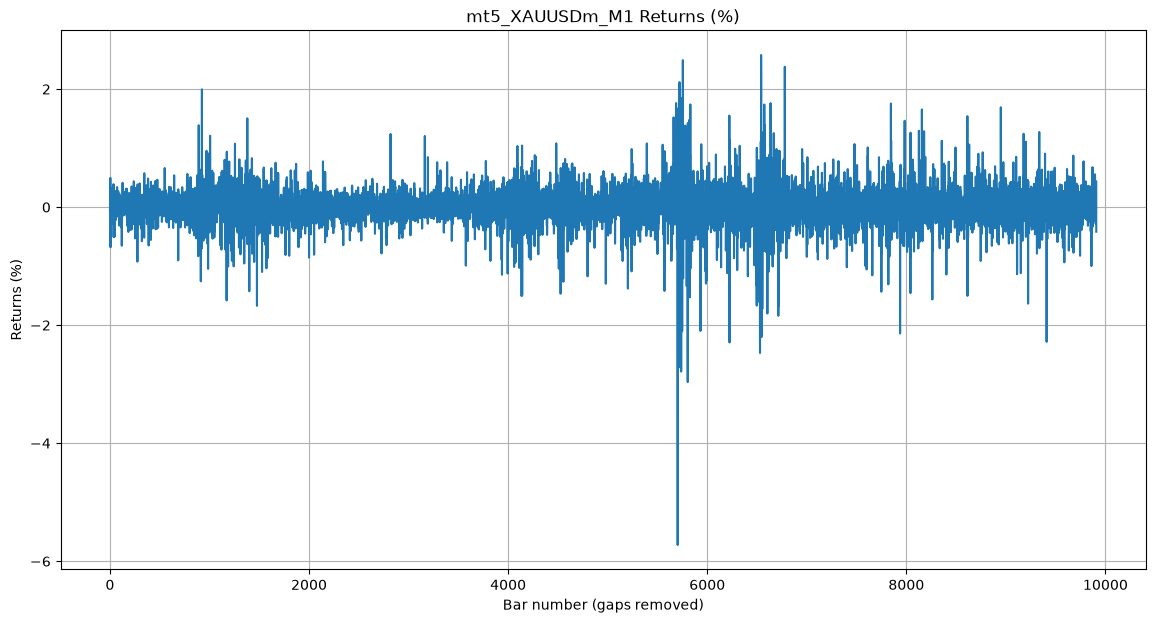

In [45]:
plt.figure(figsize=(14, 7))
plt.plot(xs(df.index), df["Series"].values)
plt.title(f"{ticker} {SERIES_LABEL}")
plt.xlabel(XLABEL)
plt.ylabel(SERIES_LABEL)
plt.grid(True)
plt.show()

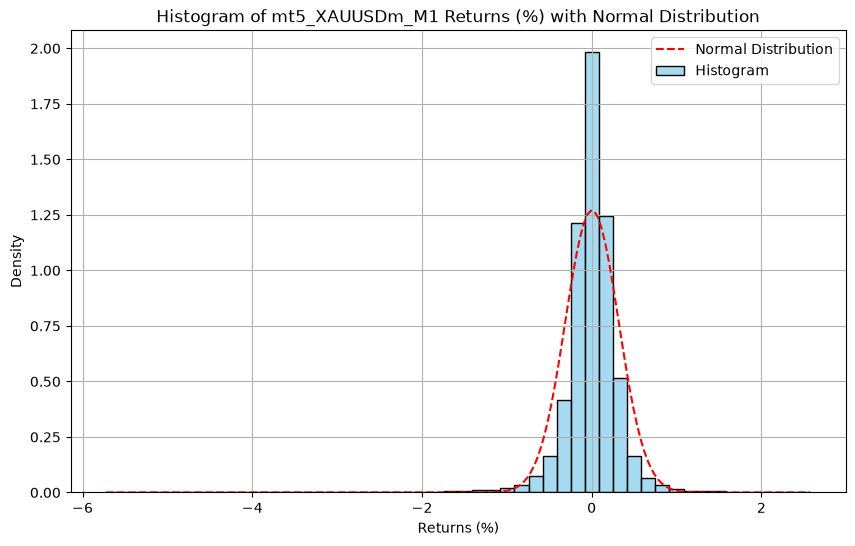

Skewness: -1.055   Excess kurtosis: 21.120   (normal = 0 and 0; fat tails if kurtosis >> 0)


In [46]:
plt.figure(figsize=(10, 6))
sns.histplot(df["Series"], bins=50, kde=False, stat="density", color="skyblue", label="Histogram")

# Overlay normal distribution
mu, std = df["Series"].mean(), df["Series"].std()
x = np.linspace(df["Series"].min(), df["Series"].max(), 200)
plt.plot(x, norm.pdf(x, mu, std), color="red", linestyle="--", label="Normal Distribution")

plt.title(f"Histogram of {ticker} {SERIES_LABEL} with Normal Distribution")
plt.xlabel(SERIES_LABEL)
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()
print(f"Skewness: {df['Series'].skew():.3f}   Excess kurtosis: {df['Series'].kurt():.3f}   (normal = 0 and 0; fat tails if kurtosis >> 0)")

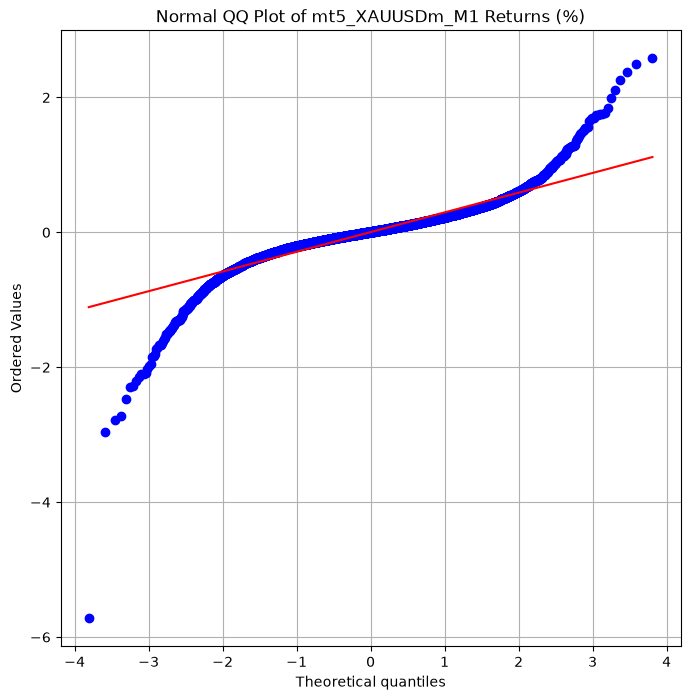

In [47]:
plt.figure(figsize=(8, 8))
probplot(df["Series"], dist="norm", plot=plt)
plt.title(f"Normal QQ Plot of {ticker} {SERIES_LABEL}")
plt.grid(True)
plt.show()

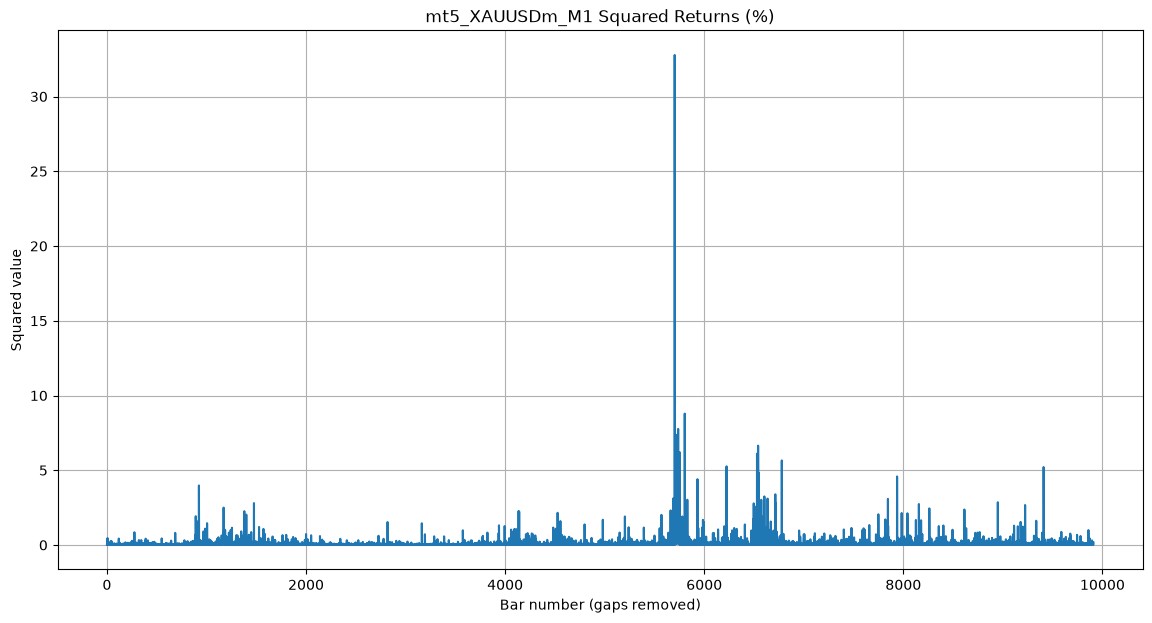

In [48]:
plt.figure(figsize=(14, 7))
plt.plot(xs(df.index), df["Squared"].values)
plt.title(f"{ticker} Squared {SERIES_LABEL}")
plt.xlabel(XLABEL)
plt.ylabel("Squared value")
plt.grid(True)
plt.show()

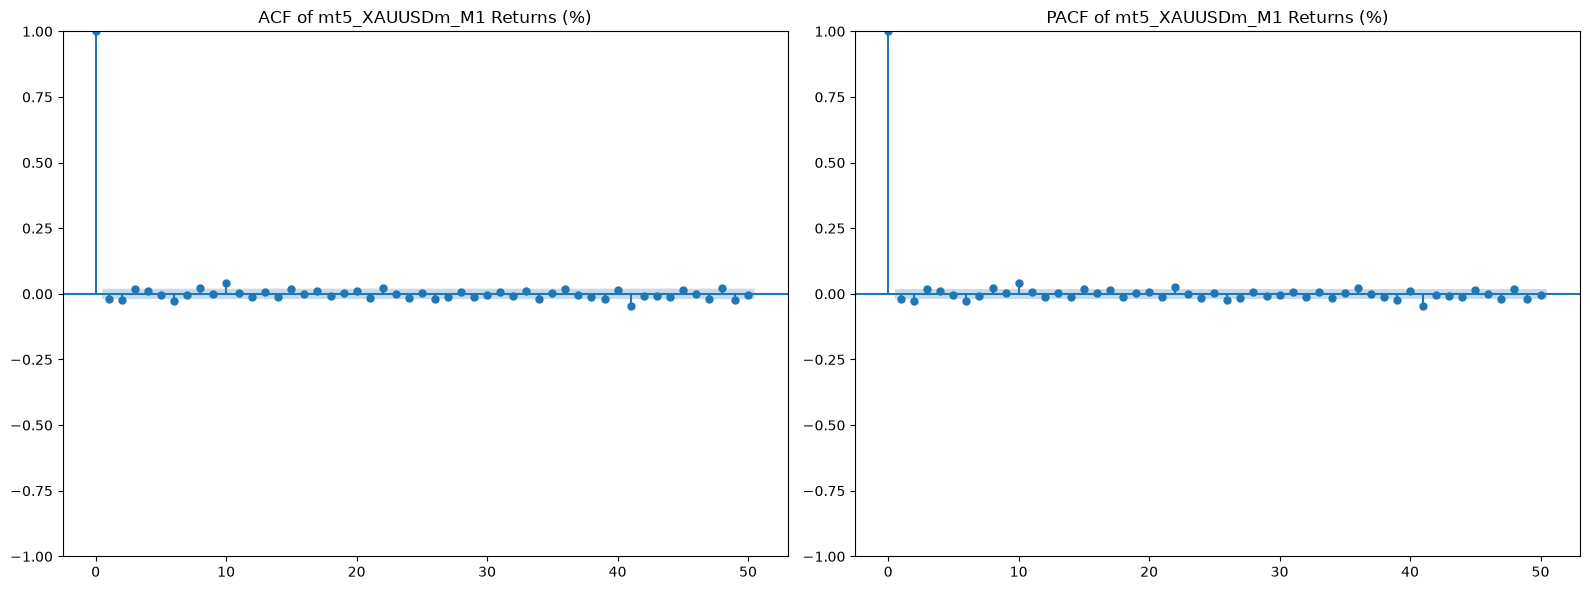

In [49]:
LAGS = max(5, min(50, len(df) // 2 - 1))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_acf(df["Series"], lags=LAGS, ax=axes[0], title=f"ACF of {ticker} {SERIES_LABEL}")
plot_pacf(df["Series"], lags=LAGS, ax=axes[1], method="ywm", title=f"PACF of {ticker} {SERIES_LABEL}")
plt.tight_layout()
plt.show()

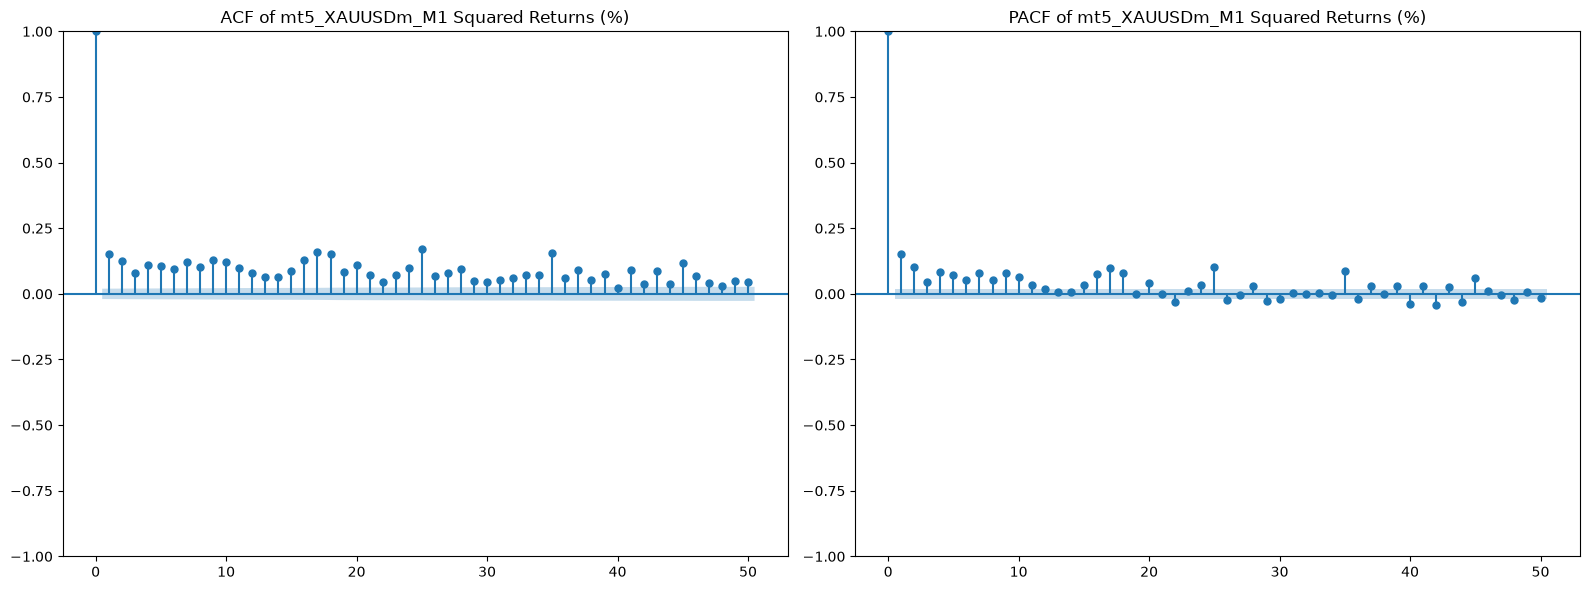

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_acf(df["Squared"], lags=LAGS, ax=axes[0], title=f"ACF of {ticker} Squared {SERIES_LABEL}")
plot_pacf(df["Squared"], lags=LAGS, ax=axes[1], method="ywm", title=f"PACF of {ticker} Squared {SERIES_LABEL}")
plt.tight_layout()
plt.show()

In [51]:
# GARCH(1,1) with Normal innovations
returns_data = df["Series"].dropna()

model_fit = fit_garch(returns_data, "normal")
print(model_fit.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Series   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1162.18
Distribution:                  Normal   AIC:                           2332.36
Method:            Maximum Likelihood   BIC:                           2361.17
                                        No. Observations:                 9909
Date:                Fri, Oct 16 2026   Df Residuals:                     9908
Time:                        22:04:26   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu         5.5463e-03  2.581e-03      2.148  3.167e-02 [4.

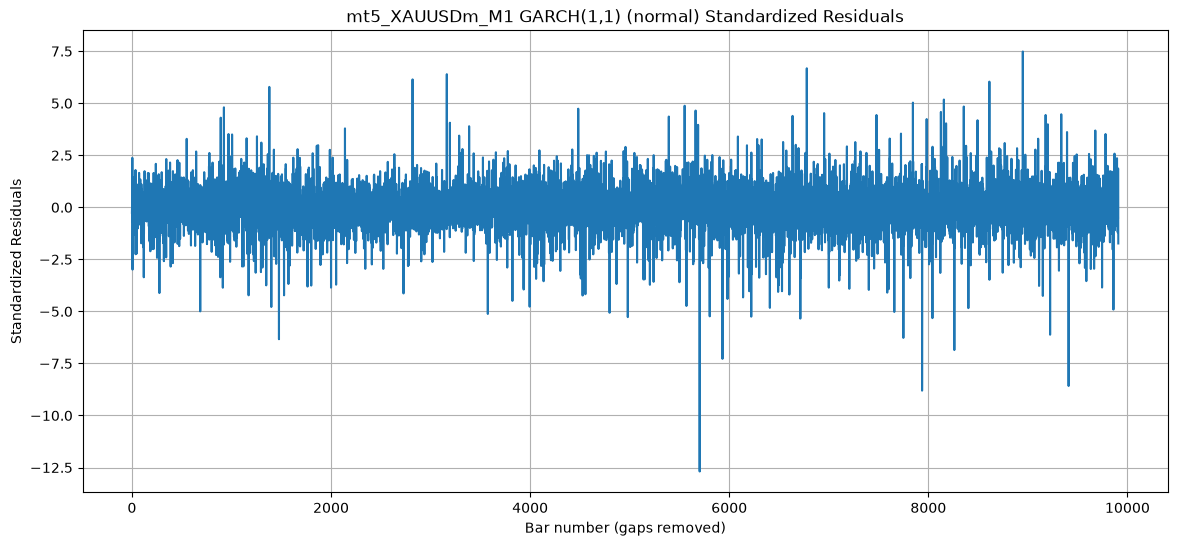

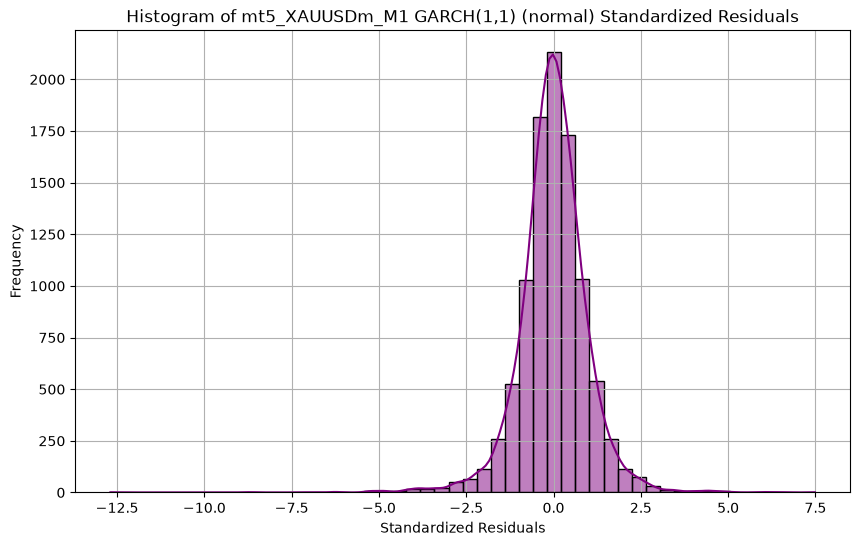

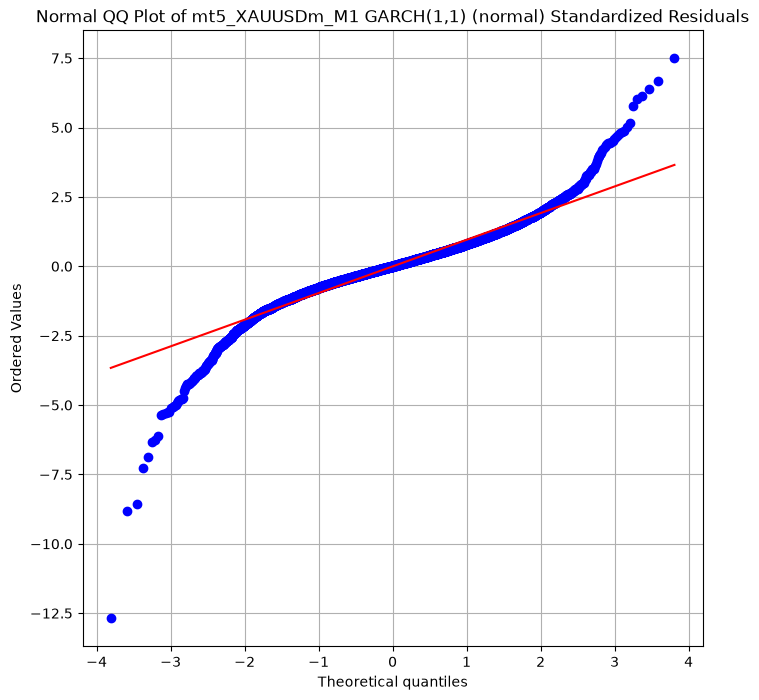

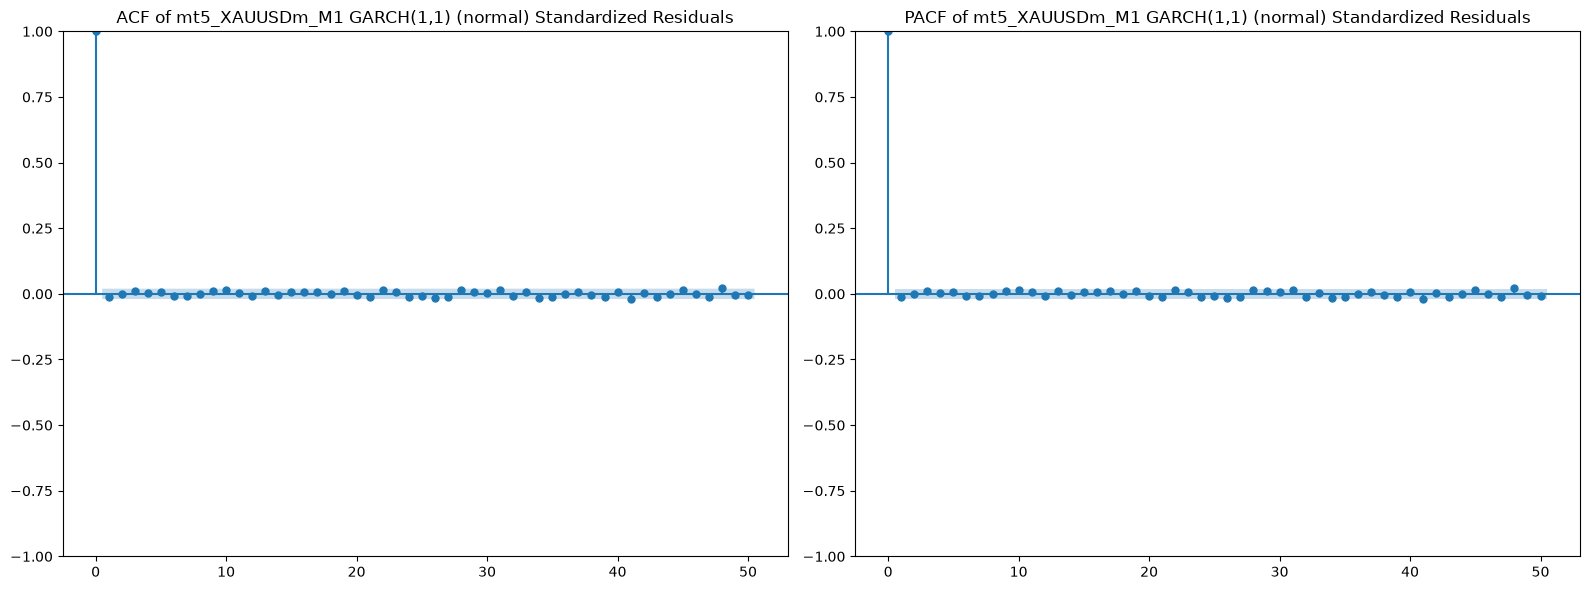

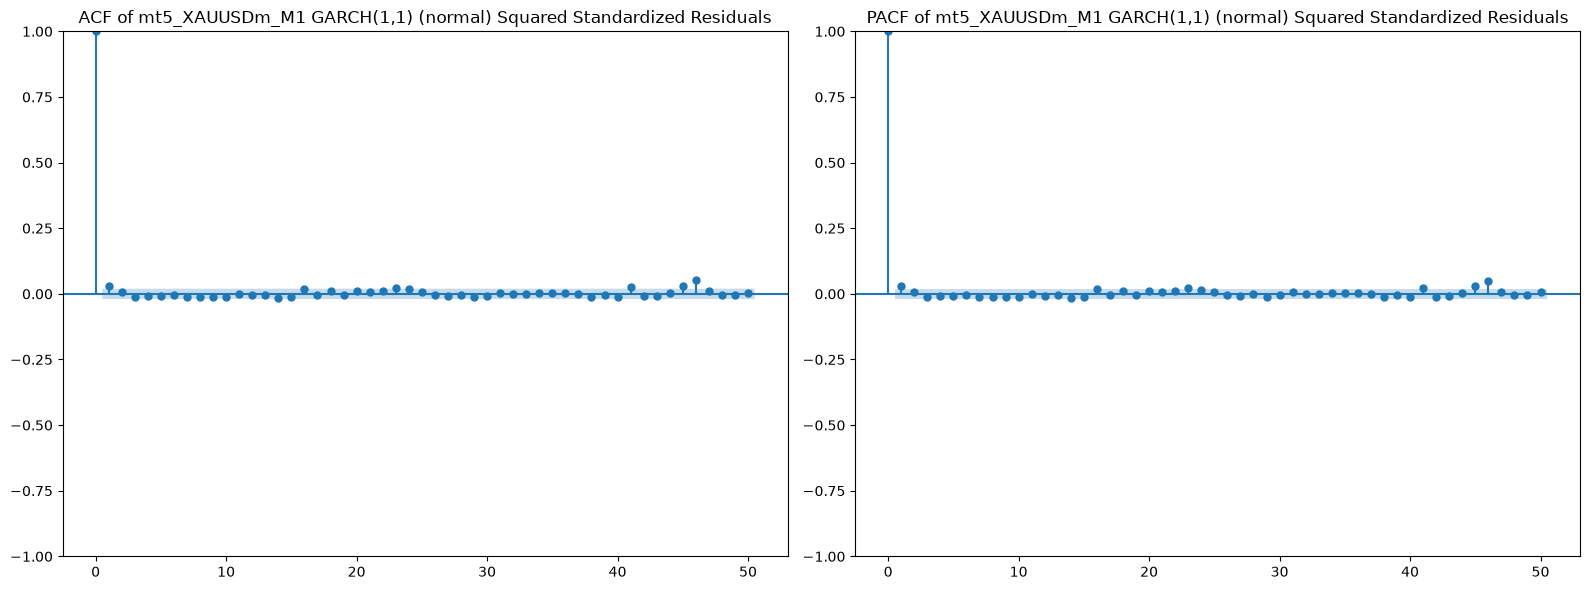

Ljung-Box on residuals          (lag 10): p = 0.6650  -> OK, no autocorrelation left
Ljung-Box on squared residuals  (lag 10): p = 0.0348  -> ARCH effects left, try GARCH(1,2) / EGARCH


In [52]:
residual_diagnostics(model_fit, "GARCH(1,1) (normal)", "normal")

In [53]:
# GARCH(1,1) with Student's t innovations (fat tails)
model_fit_t = fit_garch(returns_data, "t")
print(model_fit_t.summary())

# Normal vs t, side by side (lower AIC / BIC = better)
comparison = pd.DataFrame({
    "Normal":    {"Log-likelihood": model_fit.loglikelihood,   "AIC": model_fit.aic,   "BIC": model_fit.bic},
    "Student-t": {"Log-likelihood": model_fit_t.loglikelihood, "AIC": model_fit_t.aic, "BIC": model_fit_t.bic},
}).round(2)
display(comparison)

persistence = model_fit_t.params["alpha[1]"] + model_fit_t.params["beta[1]"]
print(f"Persistence (alpha + beta) = {persistence:.4f}",
      "-> volatility shocks fade slowly" if persistence < 1 else "-> >= 1: forecasts will NOT mean-revert, interpret with care")

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                       Series   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -211.771
Distribution:      Standardized Student's t   AIC:                           433.542
Method:                  Maximum Likelihood   BIC:                           469.548
                                              No. Observations:                 9909
Date:                      Fri, Oct 16 2026   Df Residuals:                     9908
Time:                              22:04:30   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

,Normal,Student-t
Log-likelihood,-1162.18,-211.77
AIC,2332.36,433.54
BIC,2361.17,469.55


Persistence (alpha + beta) = 0.9964 -> volatility shocks fade slowly


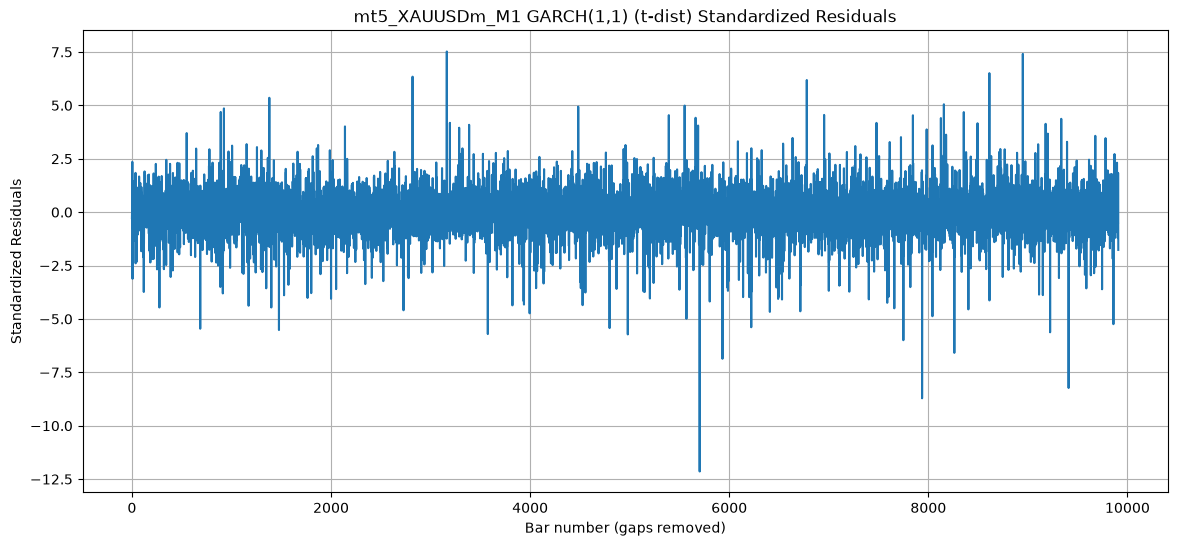

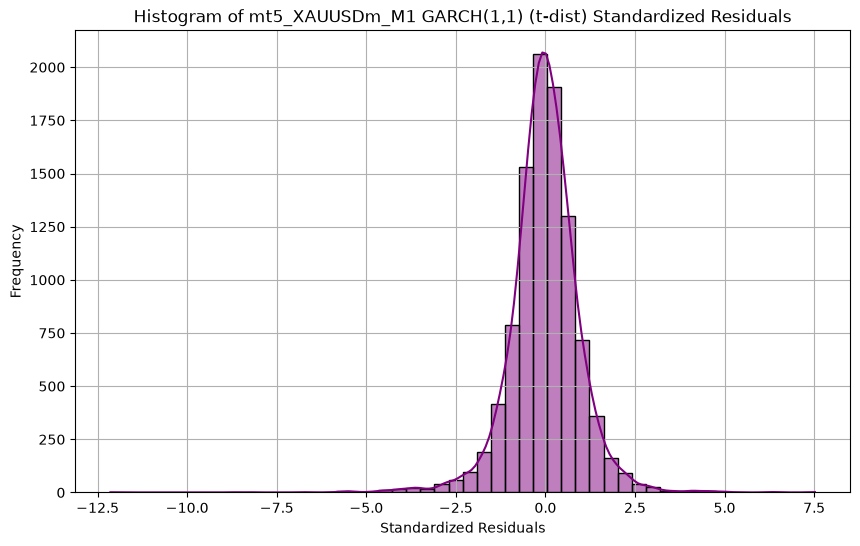

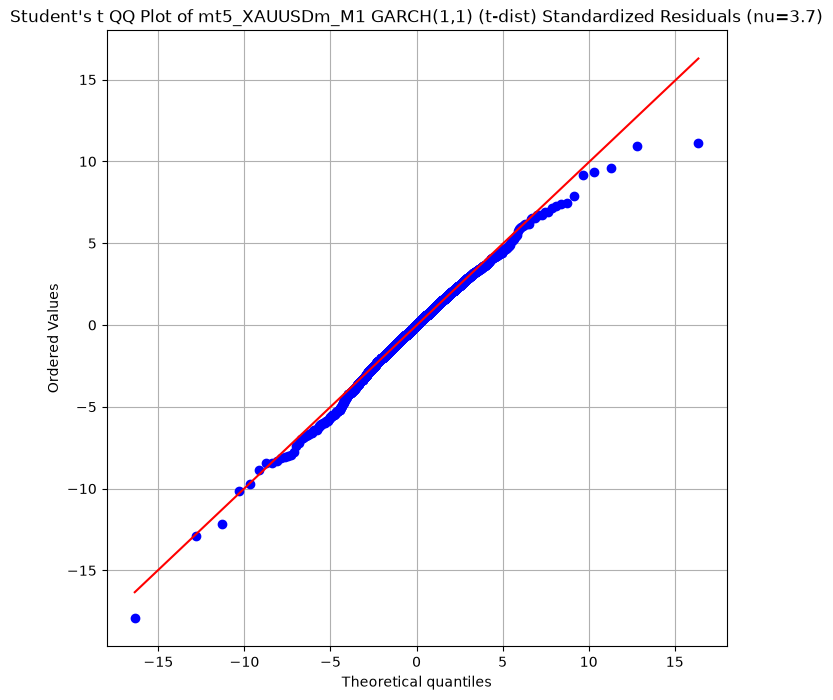

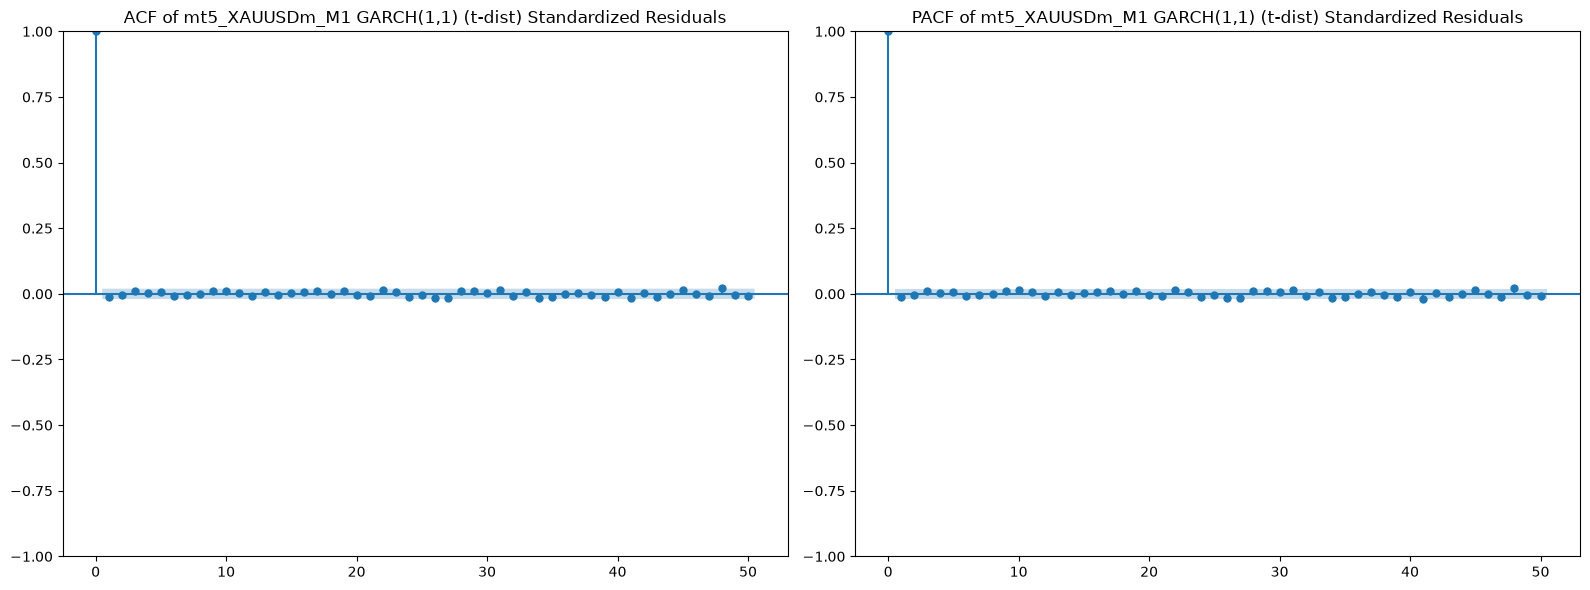

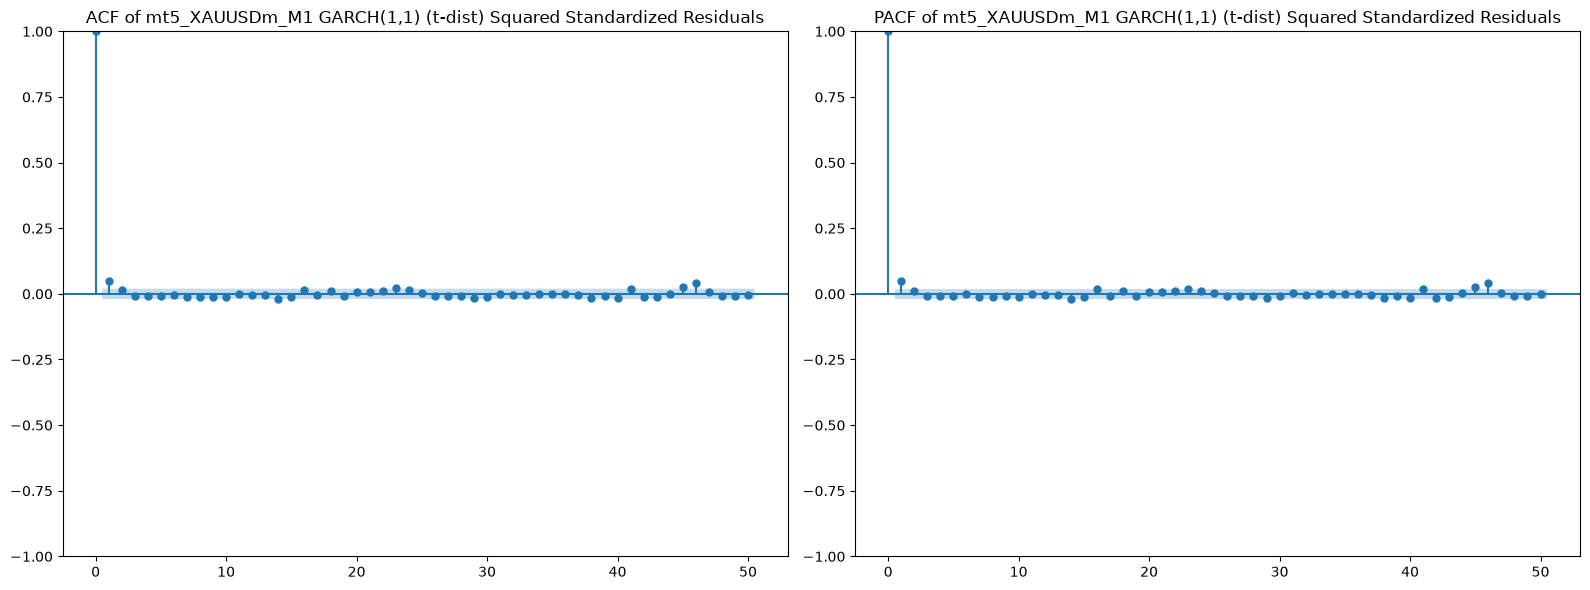

Ljung-Box on residuals          (lag 10): p = 0.6800  -> OK, no autocorrelation left
Ljung-Box on squared residuals  (lag 10): p = 0.0004  -> ARCH effects left, try GARCH(1,2) / EGARCH


In [54]:
residual_diagnostics(model_fit_t, "GARCH(1,1) (t-dist)", "t")


Forecasted Volatility for the next 15 bars:


,Forecasted Volatility (Returns (%))
bars ahead,
1,0.249749
2,0.250277
3,0.250801
4,0.251323
5,0.251842
6,0.252358
7,0.252870
8,0.253380
9,0.253888


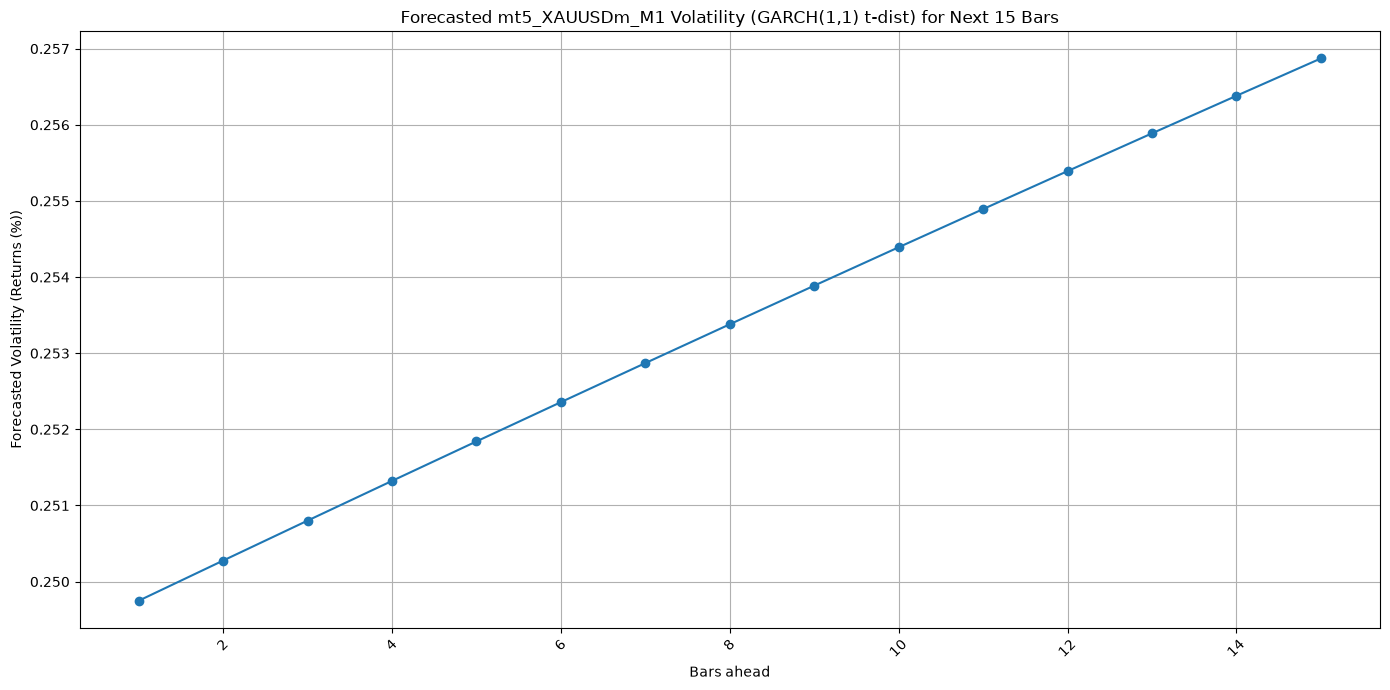

In [55]:
# ---------------------------------------------------------------------
#  Volatility forecast
# ---------------------------------------------------------------------
forecast_horizon = FORECAST_HORIZON

vol_forecast = model_fit_t.forecast(horizon=forecast_horizon, reindex=False)
var_model  = vol_forecast.variance.iloc[-1].to_numpy()    # variance per step, in model units^2
mean_model = vol_forecast.mean.iloc[-1].to_numpy()        # expected value per step, in model units
forecasted_volatility = np.sqrt(var_model)                # std per step, in model units

forecast_index = make_forecast_index(df.index, forecast_horizon, BAR_KIND)
volatility_df = pd.DataFrame({f"Forecasted Volatility ({SERIES_LABEL})": forecasted_volatility}, index=forecast_index)
volatility_df.index.name = "Date" if isinstance(forecast_index, pd.DatetimeIndex) else "bars ahead"

print(f"\nForecasted Volatility for the next {forecast_horizon} bars:")
display(volatility_df)

plt.figure(figsize=(14, 7))
plt.plot(volatility_df.index, volatility_df.iloc[:, 0], marker="o", linestyle="-")
plt.title(f"Forecasted {ticker} Volatility (GARCH(1,1) t-dist) for Next {forecast_horizon} Bars")
plt.xlabel("Date" if isinstance(forecast_index, pd.DatetimeIndex) else "Bars ahead")
plt.ylabel(f"Forecasted Volatility ({SERIES_LABEL})")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


1-sigma prediction interval for the next 15 bars  (Adjusted Close Price):


,Expected Price,Lower Bound (1-sigma),Upper Bound (1-sigma)
bars ahead,,,
1,4168.270214,4157.859994,4178.680433
2,4168.623457,4153.884375,4183.362539
3,4168.976731,4150.904592,4187.048869
4,4169.330034,4148.438499,4190.221570
5,4169.683367,4146.299584,4193.067151
6,4170.036731,4144.392317,4195.681145
7,4170.390124,4142.660017,4198.120231
8,4170.743547,4141.065803,4200.421292
9,4171.097000,4139.584088,4202.609913


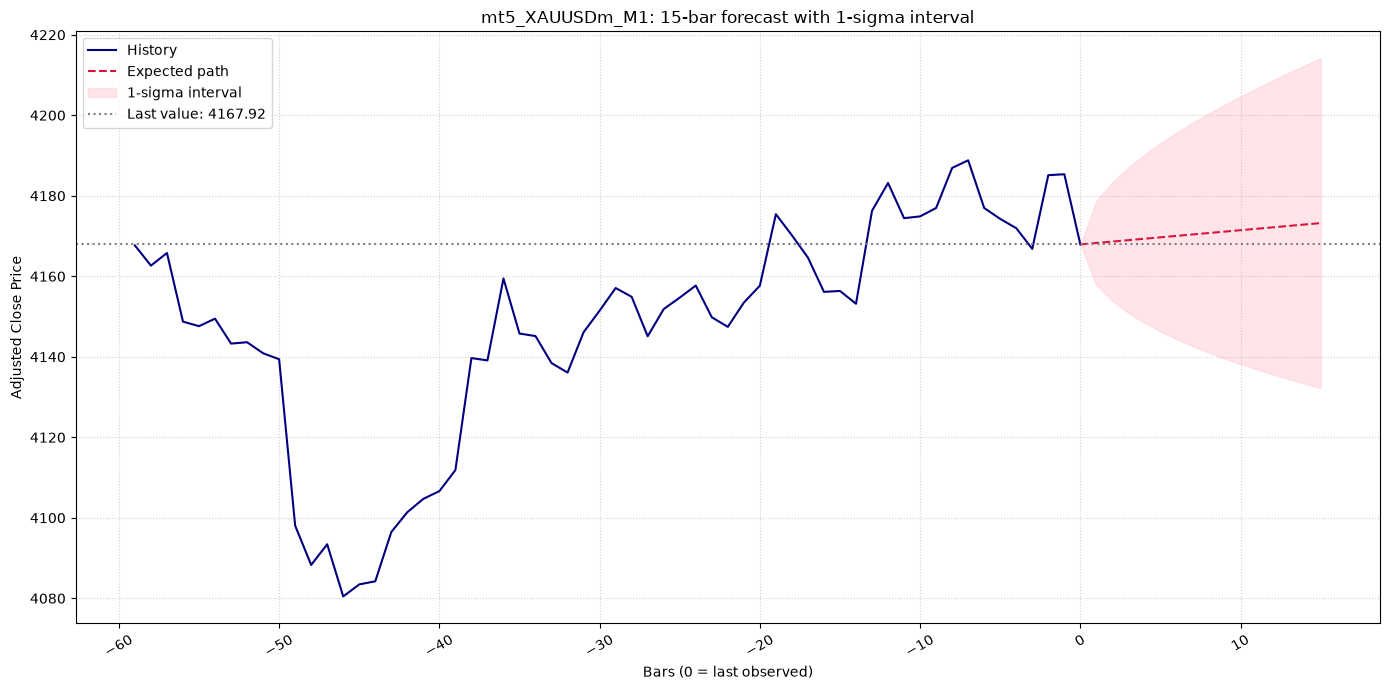

In [56]:
# ---------------------------------------------------------------------
#  Prediction interval for the price
# ---------------------------------------------------------------------
Z = 1.0          # 1.0 = 1-sigma (~68 %).  Use 1.96 for a ~95 % band.

last_close_price = float(df["Close"].iloc[-1])
mu_step = mean_model / SCALE                          # back to original units
sigma_cum = Z * np.sqrt(np.cumsum(var_model)) / SCALE # uncertainty GROWS with the horizon (variances add up)

if MODE == "pct":     # series = returns -> multiplicative price path
    expected = last_close_price * np.cumprod(1 + mu_step)
    lower = np.maximum(expected * (1 - sigma_cum), 0)
    upper = expected * (1 + sigma_cum)
else:                 # series = price changes -> additive price path
    expected = last_close_price + np.cumsum(mu_step)
    lower = expected - sigma_cum
    upper = expected + sigma_cum

prediction_df = pd.DataFrame({"Expected Price": expected,
                              f"Lower Bound ({Z:g}-sigma)": lower,
                              f"Upper Bound ({Z:g}-sigma)": upper}, index=forecast_index)
prediction_df.index.name = volatility_df.index.name
print(f"\n{Z:g}-sigma prediction interval for the next {forecast_horizon} bars  ({PRICE_LABEL}):")
display(prediction_df)

# ----- plot: recent history + forecast + band -----
hist = df["Close"].iloc[-60:]
if isinstance(forecast_index, pd.DatetimeIndex):
    xh, xf = list(hist.index), list(forecast_index)
else:
    xh, xf = list(range(-len(hist) + 1, 1)), list(forecast_index)

plt.figure(figsize=(14, 7))
plt.plot(xh, hist.values, color="navy", label="History")
plt.plot([xh[-1]] + xf, [last_close_price] + list(expected), "--", color="crimson", label="Expected path")
plt.fill_between([xh[-1]] + xf, [last_close_price] + list(lower), [last_close_price] + list(upper),
                 color="pink", alpha=0.4, label=f"{Z:g}-sigma interval")
plt.axhline(last_close_price, color="grey", linestyle=":", label=f"Last value: {last_close_price:.2f}")
plt.title(f"{ticker}: {forecast_horizon}-bar forecast with {Z:g}-sigma interval")
plt.xlabel("Date" if isinstance(forecast_index, pd.DatetimeIndex) else "Bars (0 = last observed)")
plt.ylabel(PRICE_LABEL)
plt.grid(True, linestyle=":", alpha=0.6)
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

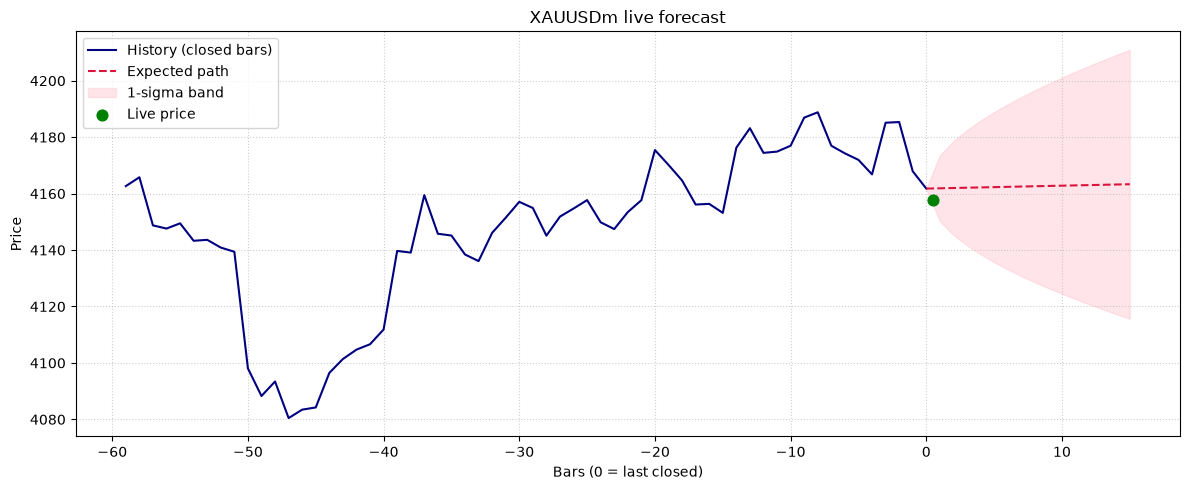

Refreshed at 22:32:59 (this computer)   |   closed-bar updates so far: 2
XAUUSDm  last closed bar: 2026-10-16 16:00:00   close: 4161.778
LIVE price : 4157.824   (bid 4157.704 / ask 4157.944)   | 57 min left in the running bar
Close range from LIVE price (1-sigma, shrinks as the bar ages): 4146.434  ...  4169.214
Close range from last CLOSE (1-sigma, fixed for this bar)     : 4150.180  ...  4173.582
Next-bar volatility: 0.2811%  (11.701 in price)  -> 29% percentile of the last 4953 bars = NORMAL volatility
15-bar 1-sigma band: 4115.681  ...  4210.970   (expected 4163.325)

Last 2 closed-bar updates:


,Price,Next-bar vol (price),Next-bar vol %,Vol percentile,Regime,Close range low,Close range high,Band low (+15),Band high (+15)
Bar time,,,,,,,,,
2026-10-16 16:00:00,4161.778,11.701,0.2811,29%,NORMAL,4150.180,4173.582,4115.681,4210.970
2026-10-16 15:00:00,4167.917,11.866,0.2847,33%,NORMAL,4156.157,4179.889,4121.322,4217.702


In [ ]:
# ---------------------------------------------------------------------
#  MT5: LIVE loop
#   - model is refitted ONLY when a new bar has closed (GARCH(1,1)-t on closed bars)
#   - screen refreshes every POLL_SECONDS with the LIVE price and a close-range re-anchored on it
#  Stop with the notebook's stop button.
# ---------------------------------------------------------------------
LIVE_BARS    = 5000      # recent bars used for each fit
LIVE_HORIZON = 15        # bars ahead
POLL_SECONDS = 10        # how often to refresh the screen / check for a new closed bar
LOG_ROWS     = 10        # how many past bar updates to keep on screen

LIVE_LOG = []            # one row per CLOSED bar (kept in memory while the loop runs)


def live_forecast(close, horizon):
    df_l, mode, _ = prepare(close, "price", drop_open=True)       # returns, gap bars removed
    scale = choose_scale(df_l["Series"], mode)
    res = fit_garch(df_l["Series"] * scale, "t")
    fc = res.forecast(horizon=horizon, reindex=False)
    var, mu = fc.variance.iloc[-1].to_numpy(), fc.mean.iloc[-1].to_numpy()
    last = float(df_l["Close"].iloc[-1])
    sig = np.sqrt(np.cumsum(var)) / scale                         # cumulative 1-sigma, as a fraction of price
    expected = last * np.cumprod(1 + mu / scale)
    lower, upper = np.maximum(expected * (1 - sig), 0), expected * (1 + sig)
    sigma1 = np.sqrt(var[0]) / scale                              # next-bar volatility, fraction of price
    pctile = float((res.conditional_volatility < np.sqrt(var[0])).mean())   # where it sits vs the recent fit window
    return df_l, last, expected, lower, upper, sigma1, pctile


def log_update(out):
    df_l, last, expected, lower, upper, sigma1, pctile = out
    d = 5 if last < 10 else 3
    regime = "HIGH" if pctile > 0.8 else "LOW" if pctile < 0.2 else "NORMAL"
    LIVE_LOG.append({"Bar time": df_l.index[-1], "Price": round(last, d),
                     "Next-bar vol (price)": round(sigma1 * last, d), "Next-bar vol %": round(sigma1 * 100, 4),
                     "Vol percentile": f"{pctile:.0%}", "Regime": regime,
                     "Close range low": round(float(lower[0]), d), "Close range high": round(float(upper[0]), d),
                     f"Band low (+{len(expected)})": round(float(lower[-1]), d),
                     f"Band high (+{len(expected)})": round(float(upper[-1]), d)})


def get_live(df_l, sigma1, step):
    """Live price + a 1-sigma close range re-anchored on it, scaled to the time left in the running bar."""
    tick = mt5.symbol_info_tick(MT5_SYMBOL)
    if tick is None or tick.bid <= 0:
        return None
    live = (tick.bid + tick.ask) / 2
    now_srv = pd.to_datetime(tick.time, unit="s")                 # broker clock
    bar_end = df_l.index[-1] + 2 * step                           # bar stamps are START times: running bar closes here
    if now_srv > bar_end + step:                                  # no ticks for the running bar -> market closed / feed paused
        return {"stale": True, "tick_time": now_srv, "bid": tick.bid, "ask": tick.ask, "live": live}
    left = float(np.clip((bar_end - now_srv) / step, 0, 1))       # fraction of the running bar still to go
    half = sigma1 * live * np.sqrt(left)                          # vol shrinks with sqrt(time left)
    return {"stale": False, "tick_time": now_srv, "bid": tick.bid, "ask": tick.ask, "live": live,
            "left_min": left * step.total_seconds() / 60, "low": live - half, "high": live + half}


def render_live(out, step):
    df_l, last, expected, lower, upper, sigma1, pctile = out
    d = 5 if last < 10 else 3                                     # decimals: forex 5, gold/indices 3
    regime = "HIGH" if pctile > 0.8 else "LOW" if pctile < 0.2 else "NORMAL"
    lv = get_live(df_l, sigma1, step)

    # ---- chart first ----
    hist = df_l["Close"].iloc[-60:]
    xh = list(range(-len(hist) + 1, 1))
    xf = [0] + list(range(1, len(expected) + 1))
    plt.figure(figsize=(12, 5))
    plt.plot(xh, hist.values, color="navy", label="History (closed bars)")
    plt.plot(xf, [last] + list(expected), "--", color="crimson", label="Expected path")
    plt.fill_between(xf, [last] + list(lower), [last] + list(upper), color="pink", alpha=0.4, label="1-sigma band")
    if lv is not None:
        plt.scatter([0.5], [lv["live"]], color="green", s=60, zorder=5, label="Live price")
    plt.title(f"{MT5_SYMBOL} live forecast"); plt.xlabel("Bars (0 = last closed)"); plt.ylabel("Price")
    plt.grid(True, linestyle=":", alpha=0.6); plt.legend(); plt.tight_layout(); plt.show(); plt.close()

    # ---- live text BELOW the chart ----
    print(f"Refreshed at {time.strftime('%H:%M:%S')} (this computer)   |   closed-bar updates so far: {len(LIVE_LOG)}")
    print(f"{MT5_SYMBOL}  last closed bar: {df_l.index[-1]}   close: {last:.{d}f}")
    if lv is None:
        print("Live price: not available right now")
    elif lv["stale"]:
        print(f"Live price: {lv['live']:.{d}f}  (last tick {lv['tick_time']} broker time - no fresh ticks, market closed?)")
    else:
        print(f"LIVE price : {lv['live']:.{d}f}   (bid {lv['bid']:.{d}f} / ask {lv['ask']:.{d}f})   "
              f"| {lv['left_min']:.0f} min left in the running bar")
        print(f"Close range from LIVE price (1-sigma, shrinks as the bar ages): {lv['low']:.{d}f}  ...  {lv['high']:.{d}f}")
    print(f"Close range from last CLOSE (1-sigma, fixed for this bar)     : {lower[0]:.{d}f}  ...  {upper[0]:.{d}f}")
    print(f"Next-bar volatility: {sigma1*100:.4f}%  ({sigma1*last:.{d}f} in price)  -> "
          f"{pctile:.0%} percentile of the last {len(df_l)} bars = {regime} volatility")
    print(f"{len(expected)}-bar 1-sigma band: {lower[-1]:.{d}f}  ...  {upper[-1]:.{d}f}   (expected {expected[-1]:.{d}f})")
    print(f"\nLast {min(LOG_ROWS, len(LIVE_LOG))} closed-bar updates:")
    display(pd.DataFrame(LIVE_LOG[-LOG_ROWS:]).set_index("Bar time").iloc[::-1])   # newest on top


def run_live():
    mt5_connect()
    last_seen, out, step = None, None, None
    try:
        while True:
            bars = mt5_bars(LIVE_BARS)
            if bars.index[-1] != last_seen:                       # a NEW bar has closed -> refit the model
                last_seen = bars.index[-1]
                out = live_forecast(bars["close"], LIVE_HORIZON)
                step = bars.index.to_series().diff().median()     # bar length (robust to weekend gaps)
                log_update(out)
            clear_output(wait=True)
            render_live(out, step)
            time.sleep(POLL_SECONDS)
    except KeyboardInterrupt:
        print("Stopped.")
    finally:
        mt5.shutdown()


run_live()
        
# “next bar” means the candle that is running right now. It’s the one that opened right after the last closed bar
'''
Last-close range: this is only a snapshot from the moment the candle opened. 
After 30 or 40 minutes of an hourly candle, price may already be far from that starting point, so the range is out of date. 
It’s the same as the live one in the first few seconds of a bar and gets worse from there.
LIVE range: it answers “where will this candle close, given where price is now and how much time is left?” It is always current, and it narrows as the candle ages.
'''

In [62]:
# To check whether any real lag is coming from MT5 (Don't run)
mt5_connect()
tick = mt5.symbol_info_tick(MT5_SYMBOL)
last_tick = pd.to_datetime(tick.time, unit="s")
print("Latest tick  (broker time):", last_tick, "| bid", tick.bid, "ask", tick.ask)
print("Last CLOSED bar (broker time):", mt5_bars(1).index[-1])
print("Your computer now (UTC):", pd.Timestamp.now("UTC").tz_localize(None).floor("s"))
print("Your computer now (local):", pd.Timestamp.now().floor("s"))
mt5.shutdown()

Connected to MT5: Exness-MT5Trial6 | symbol: XAUUSDm
Latest tick  (broker time): 2026-10-16 16:41:53 | bid 4162.767 ask 4163.007
Last CLOSED bar (broker time): 2026-10-16 15:00:00
Your computer now (UTC): 2026-10-16 16:41:50
Your computer now (local): 2026-10-16 22:11:50


True